In [1]:
#%pip install pystac-client odc-stac matplotlib numpy

Дозволяє отримати Sentinel-2 зображення в RGB заданої локації у розширенні 512х512

Обробка: Snizhkov...
  [+] Збережено: new data/Snizhkov_autumn_512.png (Дата зйомки: 2025-10-04)
Обробка: Valky...
  [+] Збережено: new data/Valky_autumn_512.png (Дата зйомки: 2025-10-04)


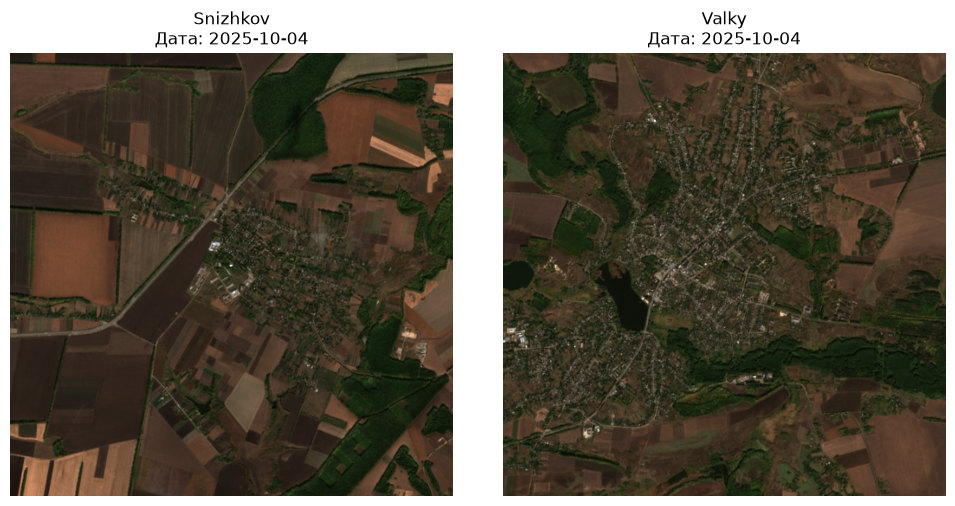

In [3]:
import os
import sys
import pystac_client
from odc.stac import stac_load
import matplotlib.pyplot as plt
import numpy as np
import math

# --- Перевірка наявності папки ---
TARGET_DIR = "new data"
if not os.path.exists(TARGET_DIR) or not os.path.isdir(TARGET_DIR):
    print(f"Помилка: Папки '{TARGET_DIR}' нема і її потрібно створити.")
    sys.exit()
# ---------------------------------

# 1. Словник локацій: Ключ - назва, Значення - кортеж (Довгота, Широта)
coords = {
    "Snizhkov": (35.508, 49.793),
    "Valky": (35.622, 49.836),
    # Додайте сюди будь-які інші локації:
    # "Kharkiv": (36.230, 49.993),
    # "Liubotyn": (35.929, 49.948)
}

def get_and_save_autumn_crop(lon, lat, location_name):
    print(f"Обробка: {location_name}...")
    bbox = [lon - 0.05, lat - 0.035, lon + 0.05, lat + 0.035]
    
    catalog = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime="2025-09-01/2025-11-30",
        query={"eo:cloud_cover": {"lt": 5}}
    )
    items = list(search.items())
    
    if not items:
        print(f"  [-] Не знайдено безхмарних знімків для {location_name}.")
        return None, None
        
    data = stac_load(
        items[:1], 
        bbox=bbox,
        bands=["red", "green", "blue"],
        resolution=10
    )
    
    red = data["red"].isel(time=0).values.astype(float)
    green = data["green"].isel(time=0).values.astype(float)
    blue = data["blue"].isel(time=0).values.astype(float)
    rgb_stack = np.dstack((red, green, blue))
    
    # Center Crop 512x512
    H, W, _ = rgb_stack.shape
    start_y = H // 2 - 256
    start_x = W // 2 - 256
    rgb_512 = rgb_stack[start_y:start_y+512, start_x:start_x+512]
    
    # Нормалізація та збереження у папку 'new data'
    rgb_normalized = np.clip(rgb_512 / 3000.0, 0, 1)
    filename = f"{location_name}_autumn_512.png"
    filepath = os.path.join(TARGET_DIR, filename)
    
    plt.imsave(filepath, rgb_normalized)
    
    capture_date = items[0].datetime.strftime('%Y-%m-%d')
    print(f"  [+] Збережено: {filepath} (Дата зйомки: {capture_date})")
    
    return rgb_normalized, capture_date

# 2. Основний цикл обробки словника
results = {}
for name, (lon, lat) in coords.items():
    img, date = get_and_save_autumn_crop(lon, lat, name)
    if img is not None:
        results[name] = {"image": img, "date": date}

# 3. Динамічна візуалізація всіх успішно завантажених зображень
n_images = len(results)
if n_images > 0:
    # Визначаємо кількість колонок (максимум 3) та рядків
    cols = min(3, n_images)
    rows = math.ceil(n_images / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    
    # Робимо axes плоским масивом для зручної ітерації
    if n_images == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
        
    for i, (name, data) in enumerate(results.items()):
        axes[i].imshow(data["image"])
        axes[i].set_title(f"{name}\nДата: {data['date']}")
        axes[i].axis('off')
        
    # Вимикаємо пусті комірки сітки (якщо зображень, наприклад, 2, а сітка 1x3)
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
else:
    print("Жодного зображення не було завантажено.")